# Airline Review Sentiment Analysis

## Overview
This project uses Natural Language Processing (NLP) and supervised machine learning to classify airline customer reviews into three sentiments Negative, Neutral, and Positive.

The workflow proceeds with data inspection and cleaning, rating-based sentiment labelling, exploratory analysis, text preprocessing, feature extraction with Bag-of-Words and TF-IDF, model comparison, and saving the selected model for deployment in a Streamlit app.

## Business problem: 
Airlines get thousands of customer reviews and reading them by hand doesn’t scale. Star ratings exist on review sites but not for other text such as emails, social media posts or survey comments. A model that reads the text and returns the sentiment lets a customer-experience team track satisfaction and spot problems without anyone reading every review.


## Objective: 
Build a model that classifies an airline review as Negative, Neutral or Positive from its text alone.

### Result in brief
The final model is **Logistic Regression with TF-IDF** (accuracy 0.87, macro-F1 0.72). Negative and Positive reviews are classified well (F1 around 0.87 to 0.93) but Neutral is the hardest class (F1 0.34), for reasons explained in the observations below.

## Import Libraries and Load the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

import string

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import classification_report, f1_score, confusion_matrix, recall_score, precision_score, accuracy_score

In [2]:
df=pd.read_csv("../data/airline_reviews.csv")
df.head() # Display the first five rows

,Unnamed: 0,Airline Name,Overall_Rating,Review_Title,Review Date,Verified,Review,Aircraft,Type Of Traveller,Seat Type,Route,Date Flown,Seat Comfort,Cabin Staff Service,Food & Beverages,Ground Service,Inflight Entertainment,Wifi & Connectivity,Value For Money,Recommended
0,0,AB Aviation,9,"""pretty decent airline""",11th November 2019,True,Moroni to Moheli. Turned out to be a pretty ...,NaN,Solo Leisure,Economy Class,Moroni to Moheli,November 2019,4.0,5.0,4.0,4.0,NaN,NaN,3.0,yes
1,1,AB Aviation,1,"""Not a good airline""",25th June 2019,True,Moroni to Anjouan. It is a very small airline...,E120,Solo Leisure,Economy Class,Moroni to Anjouan,June 2019,2.0,2.0,1.0,1.0,NaN,NaN,2.0,no
2,2,AB Aviation,1,"""flight was fortunately short""",25th June 2019,True,Anjouan to Dzaoudzi. A very small airline an...,Embraer E120,Solo Leisure,Economy Class,Anjouan to Dzaoudzi,June 2019,2.0,1.0,1.0,1.0,NaN,NaN,2.0,no
3,3,Adria Airways,1,"""I will never fly again with Adria""",28th September 2019,False,Please do a favor yourself and do not fly wi...,NaN,Solo Leisure,Economy Class,Frankfurt to Pristina,September 2019,1.0,1.0,NaN,1.0,NaN,NaN,1.0,no
4,4,Adria Airways,1,"""it ruined our last days of holidays""",24th September 2019,True,Do not book a flight with this airline! My fr...,NaN,Couple Leisure,Economy Class,Sofia to Amsterdam via Ljubljana,September 2019,1.0,1.0,1.0,1.0,1.0,1.0,1.0,no


# Data Inspection
First look at the dataset- its shape, column types, missing values and duplicates.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23171 entries, 0 to 23170
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              23171 non-null  int64  
 1   Airline Name            23171 non-null  str    
 2   Overall_Rating          23171 non-null  str    
 3   Review_Title            23171 non-null  str    
 4   Review Date             23171 non-null  str    
 5   Verified                23171 non-null  bool   
 6   Review                  23171 non-null  str    
 7   Aircraft                7129 non-null   str    
 8   Type Of Traveller       19433 non-null  str    
 9   Seat Type               22075 non-null  str    
 10  Route                   19343 non-null  str    
 11  Date Flown              19417 non-null  str    
 12  Seat Comfort            19016 non-null  float64
 13  Cabin Staff Service     18911 non-null  float64
 14  Food & Beverages        14500 non-null  float64
 

In [4]:
df.columns

Index(['Unnamed: 0', 'Airline Name', 'Overall_Rating', 'Review_Title',
       'Review Date', 'Verified', 'Review', 'Aircraft', 'Type Of Traveller',
       'Seat Type', 'Route', 'Date Flown', 'Seat Comfort',
       'Cabin Staff Service', 'Food & Beverages', 'Ground Service',
       'Inflight Entertainment', 'Wifi & Connectivity', 'Value For Money',
       'Recommended'],
      dtype='str')

In [5]:
df.isnull().sum()

Unnamed: 0                    0
Airline Name                  0
Overall_Rating                0
Review_Title                  0
Review Date                   0
Verified                      0
Review                        0
Aircraft                  16042
Type Of Traveller          3738
Seat Type                  1096
Route                      3828
Date Flown                 3754
Seat Comfort               4155
Cabin Staff Service        4260
Food & Beverages           8671
Ground Service             4793
Inflight Entertainment    12342
Wifi & Connectivity       17251
Value For Money            1066
Recommended                   0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

## Column Selection for Further Analysis and Data Cleaning
Only the columns relevant to review sentiment are kept. Some reviews have no usable rating (`n`) which will be handled before labelling.

In [7]:
cols = ['Airline Name', 'Overall_Rating', 'Review_Title','Review Date', 'Verified', 'Review', 'Type Of Traveller', 'Seat Type','Recommended']

df_reviews = df[cols].copy()
df_reviews.head()


,Airline Name,Overall_Rating,Review_Title,Review Date,Verified,Review,Type Of Traveller,Seat Type,Recommended
0,AB Aviation,9,"""pretty decent airline""",11th November 2019,True,Moroni to Moheli. Turned out to be a pretty ...,Solo Leisure,Economy Class,yes
1,AB Aviation,1,"""Not a good airline""",25th June 2019,True,Moroni to Anjouan. It is a very small airline...,Solo Leisure,Economy Class,no
2,AB Aviation,1,"""flight was fortunately short""",25th June 2019,True,Anjouan to Dzaoudzi. A very small airline an...,Solo Leisure,Economy Class,no
3,Adria Airways,1,"""I will never fly again with Adria""",28th September 2019,False,Please do a favor yourself and do not fly wi...,Solo Leisure,Economy Class,no
4,Adria Airways,1,"""it ruined our last days of holidays""",24th September 2019,True,Do not book a flight with this airline! My fr...,Couple Leisure,Economy Class,no


In [8]:
df_reviews['Recommended'].value_counts()

Recommended
no     15364
yes     7807
Name: count, dtype: int64

In [9]:
df_reviews['Overall_Rating'].value_counts().sort_index()

Overall_Rating
1    11595
2     2296
3     1356
4      859
5      830
6      675
7     1193
8     1757
9     1768
n      842
Name: count, dtype: int64

In [10]:
df_reviews[df_reviews['Overall_Rating']=='n']['Review'].head(5)

77    BRU-LJU-BRU. Outward flight on a CRJ200 very n...
78    I often fly with Adria (50 flights per year). ...
79    LGW-LJU-LGW on an older but clean A320. Outwar...
80    Frankfurt-Ljubljana-Munich in business class: ...
81    Zurich-Ljubljana return. About 2 hours+ journe...
Name: Review, dtype: str

In [11]:
df_reviews[df_reviews['Overall_Rating']=='n']['Review'].iloc[79]

"I have travelled on Air Koryo frequently for almost seven years mainly between Beijing-Pyongyang and occasionally Shenyang-Pyongyang. Flights are usually on IL-62 sometimes on TU-154 or TU-134. On one occasion on an IL-18 from Vladivostok to Pyongyang. During the 'SARS period' in 2003 when flights to China were suspended Air Koryo arranged several flights to Bangkok. The IL-62 has a reputation of being a very safe aircraft. Air Koryo pilots are most capable especially in Spring when high winds and duststorms from China are experienced. Once our flight to Beijing was unable to land due to strong winds and diverted to Tianjin for 2 hours. Air Koryo is generally punctual even departing Pyongyang (Sunan Airport) on time in snowy conditions. The flight attendants are charming but loose luggage in overhead racks (not closed bins) is of some concern to passengers also the quantities of additional hand baggage carried on board and stacked up loosely in the rear of the aircraft. The meals refe

In [12]:
df_reviews.drop(df_reviews[df_reviews['Overall_Rating']=='n']['Review'].index, inplace=True)
df_reviews[df_reviews['Overall_Rating']=='n']['Review'].head(5), df_reviews.shape


(Series([], Name: Review, dtype: str), (22329, 9))

`Overall_Rating` is stored as text because 842 reviews have the value `n` (no rating). Even though these are genuine reviews but since they are without a rating, they cannot be labelled, so they are dropped.

## Creating Sentiment Labels
Sentiment labels are created from the ratings:
- Negative: ratings 1–4
- Neutral: ratings 5–6
- Positive: ratings 7–10

Note: reviews with a rating of 1 but a recommendation of yes are reassigned a rating of 10 before sentiment labelling, probably the scraper cut "10" to "1".

In [13]:
df_reviews['rating'] = df_reviews['Overall_Rating'].astype(float)
df_reviews.loc[(df_reviews['rating'] == 1) & (df_reviews['Recommended'] == 'yes'), 'rating'] = 10
df_reviews['Sentiment'] = pd.cut(df_reviews['rating'], bins=[0,4,6,10], labels=['Negative','Neutral','Positive'])
df_reviews.head()

,Airline Name,Overall_Rating,Review_Title,Review Date,Verified,Review,Type Of Traveller,Seat Type,Recommended,rating,Sentiment
0,AB Aviation,9,"""pretty decent airline""",11th November 2019,True,Moroni to Moheli. Turned out to be a pretty ...,Solo Leisure,Economy Class,yes,9.0,Positive
1,AB Aviation,1,"""Not a good airline""",25th June 2019,True,Moroni to Anjouan. It is a very small airline...,Solo Leisure,Economy Class,no,1.0,Negative
2,AB Aviation,1,"""flight was fortunately short""",25th June 2019,True,Anjouan to Dzaoudzi. A very small airline an...,Solo Leisure,Economy Class,no,1.0,Negative
3,Adria Airways,1,"""I will never fly again with Adria""",28th September 2019,False,Please do a favor yourself and do not fly wi...,Solo Leisure,Economy Class,no,1.0,Negative
4,Adria Airways,1,"""it ruined our last days of holidays""",24th September 2019,True,Do not book a flight with this airline! My fr...,Couple Leisure,Economy Class,no,1.0,Negative


In [14]:
df_reviews['Sentiment'].value_counts(normalize=True)*100 # class balance in percent

Sentiment
Negative    61.973219
Positive    31.286668
Neutral      6.740114
Name: proportion, dtype: float64

In [15]:
# Sanity check: do the sentiment labels agree with the Recommended column? 
pd.crosstab(df_reviews['Sentiment'],df_reviews['Recommended'],margins=True, normalize='index') * 100

Recommended,no,yes
Sentiment,,
Negative,98.800405,1.199595
Neutral,49.700997,50.299003
Positive,1.531635,98.468365
All,65.058892,34.941108


- The classes are imbalanced i.e., about 62% Negative, 31% Positive and only 6.7% Neutral.
- The labels agree with the `Recommended` column: 98.8% of Negative reviews are "no" and 98.5% of Positive reviews are "yes". Neutral reviews split roughly 50-50, which shows that mid-range reviewers are genuinely mixed. This is why Neutral is the hardest class to predict.

## Exploratory Data Analysis
Class balance, airline-level patterns, review length and the vocabulary of each sentiment.

### Sentiment Distribution: 

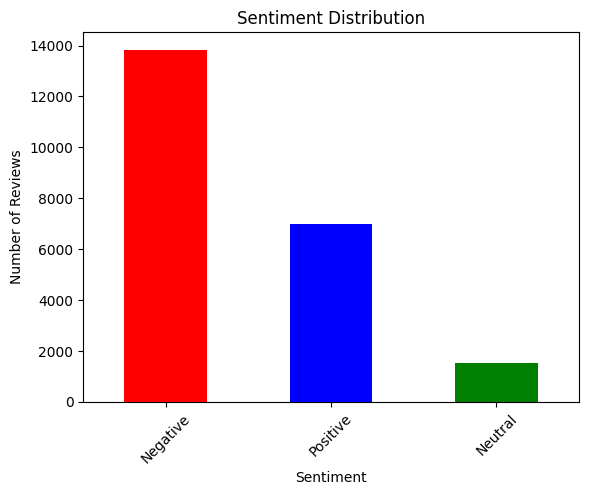

In [16]:

df_reviews['Sentiment'].value_counts().plot(kind='bar', color=['red','blue','green'], rot=45)

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()


Here we can see Negative reviews are about twice as much Positive ones and Neutral onesa are very small. That's why Accuracy alone would be misleading, so macro-F1 is used later.

### Reviews Distribution with Airlines

Text(0.5, 1.0, 'Reviews Distribution with Airlines')

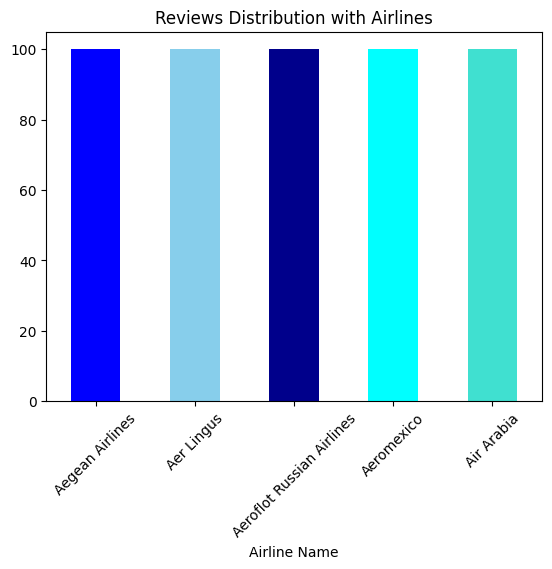

In [ ]:
df_reviews['Airline Name'].value_counts().head().plot(kind='bar', rot=45, color=['blue','skyblue','darkblue','cyan','turquoise'])
plt.title("Reviews Distribution with Airlines")

### Sentiments across Airlines

In [18]:
df_reviews['Airline Name'].value_counts().head(10)

Airline Name
Aegean Airlines              100
Aer Lingus                   100
Aeroflot Russian Airlines    100
Aeromexico                   100
Air Arabia                   100
Air Astana                   100
Air Berlin                   100
Air Canada                   100
Air Canada rouge             100
Air China                    100
Name: count, dtype: int64

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Aegean Airlines'),
  Text(1, 0, 'Aer Lingus'),
  Text(2, 0, 'Aeroflot Russian Airlines'),
  Text(3, 0, 'Aeromexico'),
  Text(4, 0, 'Air Arabia'),
  Text(5, 0, 'Air Astana'),
  Text(6, 0, 'Air Berlin'),
  Text(7, 0, 'Air Canada'),
  Text(8, 0, 'Air Canada rouge'),
  Text(9, 0, 'Air China')])

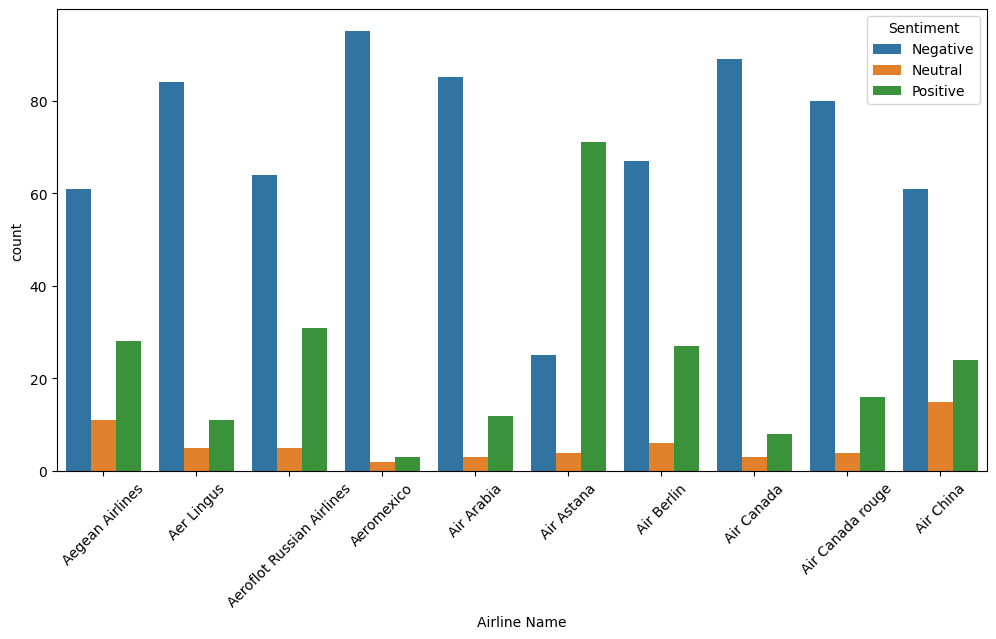

In [19]:
plt.figure(figsize=(12,6))
top=df_reviews['Airline Name'].value_counts().head(10).index
sns.countplot(data=df_reviews[df_reviews['Airline Name'].isin(top)], x='Airline Name', hue='Sentiment')
plt.xticks(rotation=45)


Sentiment still varies widely by airline. Air Astana is about 70% Positive, while Aeromexico is about 95% Negative and Air Canada about 90% Negative.

In [20]:
df_reviews['Review_length']=df_reviews['Review'].apply(len)
df_reviews

,Airline Name,Overall_Rating,Review_Title,Review Date,Verified,Review,Type Of Traveller,Seat Type,Recommended,rating,Sentiment,Review_length
0,AB Aviation,9,"""pretty decent airline""",11th November 2019,True,Moroni to Moheli. Turned out to be a pretty ...,Solo Leisure,Economy Class,yes,9.0,Positive,352
1,AB Aviation,1,"""Not a good airline""",25th June 2019,True,Moroni to Anjouan. It is a very small airline...,Solo Leisure,Economy Class,no,1.0,Negative,689
2,AB Aviation,1,"""flight was fortunately short""",25th June 2019,True,Anjouan to Dzaoudzi. A very small airline an...,Solo Leisure,Economy Class,no,1.0,Negative,405
3,Adria Airways,1,"""I will never fly again with Adria""",28th September 2019,False,Please do a favor yourself and do not fly wi...,Solo Leisure,Economy Class,no,1.0,Negative,734
4,Adria Airways,1,"""it ruined our last days of holidays""",24th September 2019,True,Do not book a flight with this airline! My fr...,Couple Leisure,Economy Class,no,1.0,Negative,597
...,...,...,...,...,...,...,...,...,...,...,...,...
23166,ZIPAIR,1,"""customer service is terrible""",5th July 2022,False,Bangkok to Tokyo. I’ve flown many low cost ai...,Couple Leisure,Economy Class,no,1.0,Negative,803
23167,ZIPAIR,1,"""Avoid at all costs""",1st June 2022,True,Avoid at all costs. I booked flights to go f...,Solo Leisure,Economy Class,no,1.0,Negative,777
23168,ZIPAIR,3,"""Will not recommend to anyone""",31st May 2022,True,Flight was leaving at 23.15 and after an hou...,Business,Economy Class,no,3.0,Negative,906
23169,ZIPAIR,6,"""It was immaculately clean""",23rd May 2022,True,Zipair is JAL’s budget airline. They don’t ha...,Business,Business Class,yes,6.0,Neutral,3109


### Distribution of review length

Text(0.5, 1.0, 'Reviews Length Distribution')

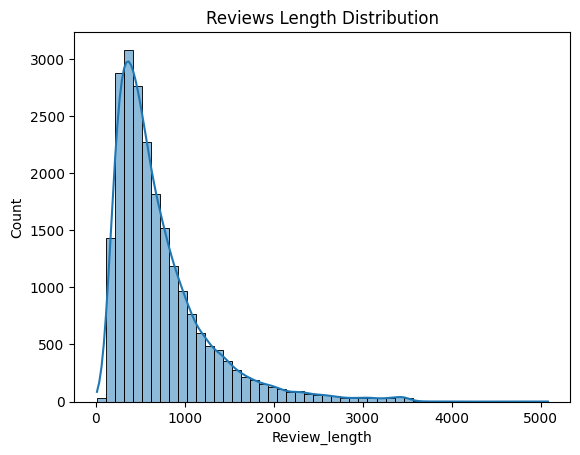

In [21]:
sns.histplot(df_reviews['Review_length'], bins=50, kde=True)
plt.title('Reviews Length Distribution')

Text(0.5, 1.0, 'Review Length Across Sentiments')

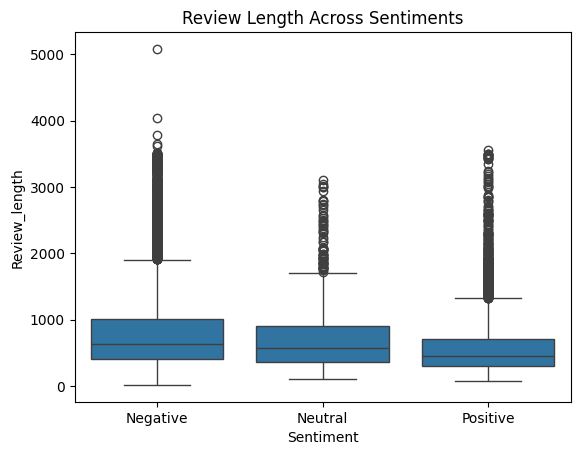

In [22]:
sns.boxplot(data=df_reviews, x='Sentiment', y='Review_length')
plt.title('Review Length Across Sentiments')

- Review length is right-skewed. The median review has about 560 characters and the longest has about 5,000.

- Negative reviews are the longest (higher median), then Neutral and Positive. Unhappy customers tend to explain what went wrong in more detail.
- Length overlaps heavily between classes so it is not a strong predictor on its own.

### Stopword list and word clouds
The stopword list is created here with negations kept and reused later in preprocessing. The word clouds show the most frequent words in each sentiment class.

In [ ]:
nltk.download('stopwords')
nltk.download('punkt_tab')
stop_words=set(stopwords.words('english'))

negations={"no", "not", "nor", "never", "don't", "doesn't", "didn't", "isn't", "wasn't", "can't", "won't"}

stop_words=stop_words-negations

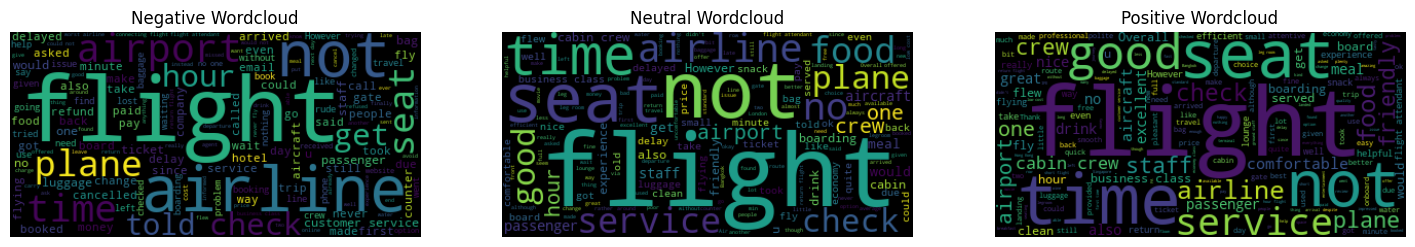

In [24]:
plt.figure(figsize=(18,8))

plt.subplot(1,3,1)

negative_text = ' '.join(df_reviews[df_reviews['Sentiment'] == 'Negative']['Review'].dropna())
negative_wc = WordCloud(stopwords=stop_words)
negative_wc.generate(negative_text)
plt.imshow(negative_wc, interpolation='bilinear')
plt.axis('off')
plt.title('Negative Wordcloud')

plt.subplot(1,3,2)

neutral_text = ' '.join(df_reviews[df_reviews['Sentiment'] == 'Neutral']['Review'].dropna())
neutral_wc = WordCloud(stopwords=stop_words)
neutral_wc.generate(neutral_text)
plt.imshow(neutral_wc, interpolation='bilinear')
plt.axis('off')
plt.title('Neutral Wordcloud')

plt.subplot(1,3,3)

positive_text = ' '.join(df_reviews[df_reviews['Sentiment'] == 'Positive']['Review'].dropna())
positive_wc = WordCloud(stopwords=stop_words)
positive_wc.generate(positive_text)
plt.imshow(positive_wc, interpolation='bilinear')
plt.axis('off')
plt.title('Positive Wordcloud')

plt.show()

## Text Preprocessing
The review title and text are combined, then cleaned step by step: lowercase, remove punctuation, digits and non-ASCII characters, tokenize, and remove stopwords while keeping negations.

In [25]:
df_reviews['Text']=df_reviews['Review_Title']+''+df_reviews['Review']

In [26]:
# Creating a dataset for model now
model_df=df_reviews[['Text', 'Sentiment']].copy()
model_df.head()

,Text,Sentiment
0,"""pretty decent airline"" Moroni to Moheli. Tur...",Positive
1,"""Not a good airline"" Moroni to Anjouan. It is ...",Negative
2,"""flight was fortunately short"" Anjouan to Dza...",Negative
3,"""I will never fly again with Adria"" Please do...",Negative
4,"""it ruined our last days of holidays"" Do not b...",Negative


In [27]:
# Step 1: lowercase
model_df['Text']=model_df['Text'].apply(lambda x: x.lower())
model_df.head()

,Text,Sentiment
0,"""pretty decent airline"" moroni to moheli. tur...",Positive
1,"""not a good airline"" moroni to anjouan. it is ...",Negative
2,"""flight was fortunately short"" anjouan to dza...",Negative
3,"""i will never fly again with adria"" please do...",Negative
4,"""it ruined our last days of holidays"" do not b...",Negative


In [28]:
# Step 2: remove punctuation
model_df['Text']=model_df['Text'].apply(lambda x: x.translate(str.maketrans('','',string.punctuation)))
model_df.head()

,Text,Sentiment
0,pretty decent airline moroni to moheli turned...,Positive
1,not a good airline moroni to anjouan it is a v...,Negative
2,flight was fortunately short anjouan to dzaou...,Negative
3,i will never fly again with adria please do a...,Negative
4,it ruined our last days of holidays do not boo...,Negative


In [29]:
# Step 3: remove digits
def remove_num(txt):
    new=""
    for i in txt:
        if not i.isdigit():
            new=new+i
    return new

model_df['Text']=model_df['Text'].apply(remove_num)
model_df.head()

,Text,Sentiment
0,pretty decent airline moroni to moheli turned...,Positive
1,not a good airline moroni to anjouan it is a v...,Negative
2,flight was fortunately short anjouan to dzaou...,Negative
3,i will never fly again with adria please do a...,Negative
4,it ruined our last days of holidays do not boo...,Negative


In [30]:
# Step 4: remove emojis and other non-ASCII characters
def remove_emojis(txt):
    new=""
    for i in txt:
        if i.isascii():
            new=new+i
    return new

model_df['Text']=model_df['Text'].apply(remove_emojis)
model_df.head()

,Text,Sentiment
0,pretty decent airline moroni to moheli turned...,Positive
1,not a good airline moroni to anjouan it is a v...,Negative
2,flight was fortunately short anjouan to dzaou...,Negative
3,i will never fly again with adria please do a...,Negative
4,it ruined our last days of holidays do not boo...,Negative


In [31]:
model_df['Text'][1]

'not a good airline moroni to anjouan it is a very small airline my ticket advised me to turn up at hrs which i did there was confusion at this small airport i was then directed to the office of ab aviation which was still closed it opened at hrs and i was told that the flight had been put back to hrs and that they had tried to contact me this could not be true as they did not have my phone number i was with a local guide and he had not been informed either i presume that i was bumped off the later flight did operate but as usual there was confusion at checkin the flight was only mins and there were no further problems not a good airline but it is the only one for comoros'

In [32]:
# Step 5: tokenize and drop stopwords (negations are kept so "not good" stays intact)
def remove(txt):
    words=word_tokenize(txt)
    cleaned=[]
    for i in words:
        if not i in stop_words:
            cleaned.append(i)
    return ' '.join(cleaned)

model_df['Text']=model_df['Text'].apply(remove)

model_df['Text'][1]



'not good airline moroni anjouan small airline ticket advised turn hrs confusion small airport directed office ab aviation still closed opened hrs told flight put back hrs tried contact could not true not phone number local guide not informed either presume bumped later flight operate usual confusion checkin flight mins no problems not good airline one comoros'

## Train-Test Split and Feature Extraction
The data is split 80/20 (stratified), then converted to numeric features. Vectorizers are fitted on the training set only to avoid data leakage.

In [33]:
X=model_df['Text']
y=model_df['Sentiment']

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [35]:
# Bag-of-Words with unigrams and bigrams
bow=CountVectorizer(ngram_range=(1,2))
X_train_bow=bow.fit_transform(X_train)
X_test_bow=bow.transform(X_test)
X_train_bow, X_test_bow

(<Compressed Sparse Row sparse matrix of dtype 'int64'
 	with 2184193 stored elements and shape (17863, 620310)>,
 <Compressed Sparse Row sparse matrix of dtype 'int64'
 	with 425536 stored elements and shape (4466, 620310)>)

## Model Training and Evaluation
Five model and feature combinations are trained and evaluated. Because Neutral is a small class, **macro-F1** (which weights all classes equally) is used to compare models, not accuracy alone.

### Naive Bayes with Bag-of-Words

Accuracy: 0.8593819973130318
Classification Report:
               precision    recall  f1-score   support

    Negative       0.88      0.96      0.92      2768
     Neutral       0.00      0.00      0.00       301
    Positive       0.81      0.85      0.83      1397

    accuracy                           0.86      4466
   macro avg       0.57      0.60      0.58      4466
weighted avg       0.80      0.86      0.83      4466



c:\Users\hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

Text(50.722222222222214, 0.5, 'Actual labels')

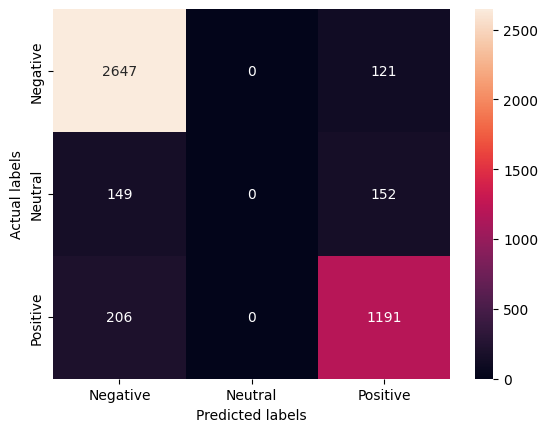

In [36]:
nb_model=MultinomialNB()
nb_model.fit(X_train_bow,y_train)
pred_nb=nb_model.predict(X_test_bow)
print("Accuracy:", accuracy_score(y_test, pred_nb))

print("Classification Report:\n", classification_report(y_test,pred_nb))
cm=confusion_matrix(y_test, pred_nb)
sns.heatmap(cm,annot=True, fmt='d', xticklabels=['Negative', 'Neutral', 'Positive'], yticklabels=['Negative', 'Neutral', 'Positive'])
plt.xlabel('Predicted labels')
plt.ylabel('Actual labels')

### Naive Bayes with TF-IDF

Accuracy: 0.7566054635020152
Classification Report:
               precision    recall  f1-score   support

    Negative       0.73      0.99      0.84      2768
     Neutral       0.00      0.00      0.00       301
    Positive       0.91      0.45      0.60      1397

    accuracy                           0.76      4466
   macro avg       0.55      0.48      0.48      4466
weighted avg       0.74      0.76      0.71      4466



c:\Users\hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

Text(50.722222222222214, 0.5, 'Actual labels')

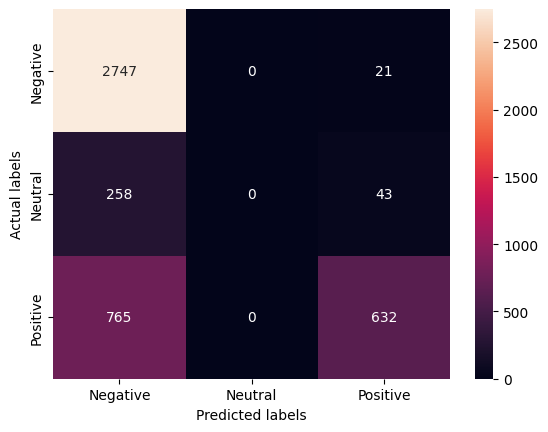

In [37]:
# TF-IDF with unigrams and bigrams (fit on the training set only)
tfidf=TfidfVectorizer(ngram_range=(1,2))
X_train_tfidf=tfidf.fit_transform(X_train)
X_test_tfidf=tfidf.transform(X_test)


# Naive Bayes on TF-IDF features
nb_model_2=MultinomialNB()
nb_model_2.fit(X_train_tfidf,y_train)

pred_nb_2=nb_model_2.predict(X_test_tfidf)
print('Accuracy:', accuracy_score(y_test, pred_nb_2))

print('Classification Report:\n',classification_report(y_test,pred_nb_2))
cm=confusion_matrix(y_test, pred_nb_2)
sns.heatmap(cm,annot=True, fmt='d', xticklabels=['Negative', 'Neutral', 'Positive'], yticklabels=['Negative', 'Neutral', 'Positive'])
plt.xlabel('Predicted labels')
plt.ylabel('Actual labels')

It predicts almost everything as Negative (Negative recall 0.99, Positive recall 0.45) and still never predicts Neutral. This variant is dropped from the final comparison. It is the worst performing model.

### Logistic Regression with Bag-of-Words

Accuracy:  0.8804299149126735
Classification Report:
               precision    recall  f1-score   support

    Negative       0.92      0.94      0.93      2768
     Neutral       0.33      0.21      0.26       301
    Positive       0.87      0.90      0.88      1397

    accuracy                           0.88      4466
   macro avg       0.71      0.68      0.69      4466
weighted avg       0.87      0.88      0.87      4466



Text(50.722222222222214, 0.5, 'Actual labels')

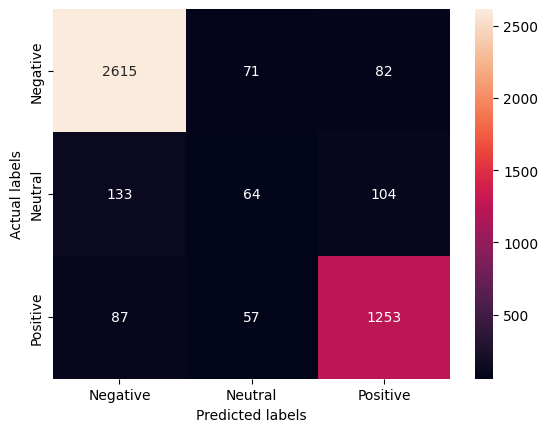

In [38]:
lr_model_bow= LogisticRegression(max_iter=1000, class_weight='balanced') # class_weight='balanced' compensates for the small Neutral class 
lr_model_bow.fit(X_train_bow, y_train)
pred_lr_bow=lr_model_bow.predict(X_test_bow)
print('Accuracy: ',accuracy_score(y_test,pred_lr_bow))
print('Classification Report:\n', classification_report(y_test,pred_lr_bow))
cm=confusion_matrix(y_test, pred_lr_bow)
sns.heatmap(cm,annot=True, fmt='d', xticklabels=['Negative', 'Neutral', 'Positive'], yticklabels=['Negative', 'Neutral', 'Positive'])
plt.xlabel('Predicted labels')
plt.ylabel('Actual labels')




### Logistic Regression with TF-IDF

Accuracy:  0.8712494402149574
Classification Report:
               precision    recall  f1-score   support

    Negative       0.94      0.92      0.93      2768
     Neutral       0.33      0.36      0.34       301
    Positive       0.86      0.88      0.87      1397

    accuracy                           0.87      4466
   macro avg       0.71      0.72      0.72      4466
weighted avg       0.87      0.87      0.87      4466



Text(50.722222222222214, 0.5, 'Actual labels')

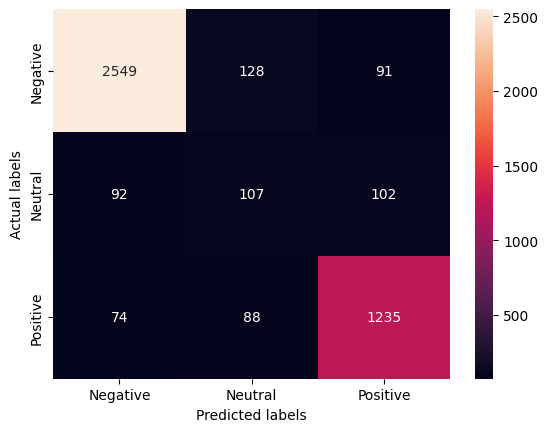

In [39]:
lr_model_tfidf= LogisticRegression(max_iter=1000, class_weight='balanced') # Logistic Regression on TF-IDF with balanced class weights
lr_model_tfidf.fit(X_train_tfidf, y_train)

pred_lr=lr_model_tfidf.predict(X_test_tfidf)
print('Accuracy: ',accuracy_score(y_test,pred_lr))
print("Classification Report:\n",classification_report(y_test,pred_lr))
cm=confusion_matrix(y_test, pred_lr)
sns.heatmap(cm,annot=True, fmt='d', xticklabels=['Negative', 'Neutral', 'Positive'], yticklabels=['Negative', 'Neutral', 'Positive'])
plt.xlabel('Predicted labels')
plt.ylabel('Actual labels')

### Linear SVM with TF-IDF

Accuracy:  0.8945364979847739
Classification Report:
               precision    recall  f1-score   support

    Negative       0.92      0.96      0.94      2768
     Neutral       0.53      0.12      0.20       301
    Positive       0.87      0.92      0.89      1397

    accuracy                           0.89      4466
   macro avg       0.77      0.67      0.68      4466
weighted avg       0.88      0.89      0.88      4466



Text(50.722222222222214, 0.5, 'Actual labels')

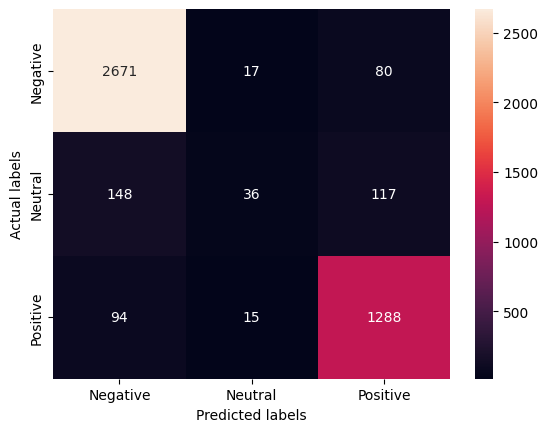

In [40]:
svm=LinearSVC(class_weight='balanced')
svm.fit(X_train_tfidf, y_train)
pred_svm=svm.predict(X_test_tfidf)

print("Accuracy: ",accuracy_score(y_test,pred_svm))
print("Classification Report:\n",classification_report(y_test,pred_svm))
cm=confusion_matrix(y_test, pred_svm)
sns.heatmap(cm,annot=True, fmt='d', xticklabels=['Negative', 'Neutral', 'Positive'], yticklabels=['Negative', 'Neutral', 'Positive'])
plt.xlabel('Predicted labels')
plt.ylabel('Actual labels')

## Model Comparison and Final Model Selection
Final test-set comparison of the three main models, each scored on the features it was trained on.

In [41]:
models = {
    'Naive Bayes':            (nb_model, X_test_bow),
    'Logistic Regression': (lr_model_tfidf, X_test_tfidf),
    'Linear SVM':          (svm, X_test_tfidf)
}

results = []

for name, (model,X) in models.items():

    y_pred = model.predict(X)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='macro'),
        'Macro F1': f1_score(y_test, y_pred, average='macro')
    })

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,Macro F1
0,Naive Bayes,0.8594,0.5651,0.6029,0.5834
1,Logistic Regression,0.8712,0.7117,0.7201,0.7157
2,Linear SVM,0.8945,0.7712,0.6688,0.6764


- **Logistic Regression (TF-IDF) is selected as the final model.** It has the best macro-F1 (0.716) and recall (0.720). The SVM has higher accuracy (0.895) and precision, but this comes from the Negative and Positive classes while Neutral is mostly missed.
- Naive Bayes is clearly the weakest (macro-F1 0.58), as expected for a baseline.
- Neutral remains the weak spot for every model. Reviews rated 5-6 are ambiguous, and their authors are split 50/50 on recommending the airline, so a text model cannot separate them cleanly.

## Save the Final Model
The selected model and the fitted TF-IDF vectorizer are saved for building the web-app.

In [42]:
import joblib as jl
from pathlib import Path

MODEL_DIR =Path("../model")

jl.dump(lr_model_tfidf, MODEL_DIR / "airlines_sentiment_model.pkl")
jl.dump(tfidf, MODEL_DIR / "tfidf_vectorizer.pkl")

['..\\model\\tfidf_vectorizer.pkl']